<!-- This is a template that you should use to generate your lab reports for AE801 course work-->
# **Lab Report: Interpolation**

# Required packages

In [24]:
# do not change line below
#from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

# Problem statement

Reconstruct a smooth function and a cambered airfoil from a finite set of data points using interpolation.

# Approach and numerical method

### Cambered four-digit NACA airfoil
The NACA airfoil series is a set of standardised airfoil shapes, developed by NACA.\

The NACA four-digit wing sections define the profile by:
- The first digit describes maximum camber as a percentage of the chord.
- The second digit describes the distance of maximum camber from the airfoil leading edge in tenths of the chord.
- The last two digits describe the airfoil's maximum thickness as a per cent of the chord.

For example, the NACA 2412 airfoil has a maximum camber of 2% located 40% (0.4 chords) from the leading edge with a maximum thickness of 12% of the chord.

The equations for a 4-digit NACA airfoil are given below:\
The half-thickness profile is given by the following equation:

- **Thickness Equation:**
  $$y_t = 5t \left[ 0.2969\sqrt{x} - 0.1260x - 0.3516x^2 + 0.2843x^3 - 0.1015x^4 \right]$$

Where:
- **$x$**: Position along the chord, normalized from $0$ to $1.00$ ($0\%$ to $100\%$).
- **$y_t$**: Half-thickness at a given value of $x$ (measured from the centerline to the surface).
- **$t$**: Maximum thickness expressed as a fraction of the chord length. 
     *Note:* This value corresponds to the last two digits of the NACA 4-digit designation divided by 100.

The formula used to calculate the mean camber line ($y_c$) is a piecewise function:

- **Mean Camber Line ($y_c$):**
  $$y_c = \begin{cases} \dfrac{m}{p^2}\left(2px - x^2\right), & 0 \leq x \leq p \\ \dfrac{m}{(1-p)^2}\left((1-2p) + 2px - x^2\right), & p \leq x \leq 1 \end{cases}$$

Where:
- **$m$**: Maximum camber. (e.g., $100m$ forms the first digit of the NACA code).
- **$p$**: Location of the maximum camber. (e.g., $10p$ forms the second digit).
    - *Example:* A **NACA 2412** airfoil has a $2\%$ maximum camber ($m = 0.02$) located at $40\%$ of the chord ($p = 0.4$), with a thickness of $12\%$ ($t = 0.12$).

Because thickness must be applied strictly perpendicular to the camber line, the final surface coordinates are shifted by an angle $\theta$:

- **Surface Mapping:**
  $$\begin{aligned} x_U &= x - y_t \sin\theta, & y_U &= y_c + y_t \cos\theta \\ x_L &= x + y_t \sin\theta, & y_L &= y_c - y_t \cos\theta \end{aligned}$$

Where:
- **$(x_U, y_U)$**: Coordinates of the upper airfoil surface.
- **$(x_L, y_L)$**: Coordinates of the lower airfoil surface.
- **$\theta$**: The local slope angle of the mean camber line, calculated as:
  $$\theta = \arctan\left(\frac{dy_c}{dx}\right)$$
- **Camber Line Derivative ($\frac{dy_c}{dx}$):**
  $$\frac{dy_c}{dx} = \begin{cases} \dfrac{2m}{p^2}\left(p - x\right), & 0 \leq x \leq p \\ \dfrac{2m}{(1-p)^2}\left(p - x\right), & p \leq x \leq 1 \end{cases}$$
### Lagrange interpolation
For $N+1$ data points, the Lagrange polynomial is given by: \
$f_n (x) = \sum_{i=0}^{N} \, f(x_i)\, L_i (x)$

where $L_i (x)$ are the Lagrange basis polynomials, given  by:
$L_i (x) = \prod_{\substack{j=0 \\j \neq i }}^{N} \frac{x-x_j}{x_i-x_j}$

The polynomial constructed this way passes exactly through every data point and has degree at most N.

### Cubic Spline interpolation
The method fits a series of cubic polynomials between each pair of points in a given set of scattered data points. These polynomials join smoothly and make the curve look natural and continuous. 
For data points $(x_0 , y_0)$, $(x_1, y_1)$, $...$, $(x_n,y_n)$, and we fit cubic polynomials $S_i(x)$ over each interval $[x_i, x_{i+1}]$ such that: \
$S_i(x) = a_i + b_i(x-x_i)+c_i(x-x_i)^2 + d_i(x-x_i)^3$

We define $h_i=x_{i+1}-x_i$, and define second derivatives at the knots as $M_i=S''(x_i)$. From Taylor's approximation and spline properties: \
$\frac{y_{i+1}-y_i}{h_i} = \frac{h_i}{6}M_i + \frac{h_i}{3}M_{i+1}+linear \,term$

Which gives us a spline equation: \
$\mu_i M_{i-1}+2M_i+ \lambda_i M_{i+1} = d_i$

where, 
- $\mu_i = \frac{h_i}{h_i+h_{i+1}},$ $\lambda_i = 1-\mu_i$
- $d_i = \frac{6}{h_i+h_{i+1}}(\frac{y{i+1}-y_i}{h_{i+1}}-\frac{y_i-y_{i-1}}{h_i})$

This gives a tridiagonal matrix system to solve for $M_0, M_1, ..., M_n$. Once the second derivatives of $M_i$ are solved from the above-mentioned equations, then the spline on each interval is given by: \
$S_i(x) = \frac{M_{i+1}(x-x_i)^3}{6h_i}+\frac{M_i(x_{i+1}-x)^3}{6h_i}+A(x-x_i)+B(x_{i+1}-x)$

Where A and B are constants and depend on $y_i,y_{i+1}$ and $M_i, M_{i+1}$.

Applications of cubic spline interpolation:
- Used for smooth curve modelling and motion paths in design and animation.
- Used to design smooth mechanical components, surfaces and motion trajectories.
- Used to produce smooth curves from experimental or observed data in physics, biology, or economics.

### Error calculations
The accuracy is quantified using the maximum absolute error and the RMS error.
To quantify errors, we calculate the errors between the following: \
$1.$ Actual airfoil coordinates: $y_{true}$ \
$2.$ Coordinates using the Lagrange function: $ y_{reconstruct} $ 


The maximum error is calculated using the formula below: \
$E_{max} = max|y_{true} - y_{reconstruct}|$

The RMS, or the root mean square error, is given below: \
$E_{RMS} = \sqrt{\frac{1}{N} \sum_{i=1}^{n} \left( y_{true, i} - y_{reconstruct, i} \right)^2}$


# Numerical algorithm

NACA 2819
max camber =  0.02
location of max camber =  0.8
thickness ratio =  0.19
Generated airfoil: NACA 2819
[ 0.00000000e+00  1.23852969e-02  1.73714821e-02  2.11381134e-02
  2.42721884e-02  2.70010838e-02  2.94414182e-02  3.16624739e-02
  3.37093962e-02  3.56135474e-02  3.73977654e-02  3.90792940e-02
  4.06715328e-02  4.21851405e-02  4.36287612e-02  4.50095212e-02
  4.63333781e-02  4.76053734e-02  4.88298181e-02  5.00104339e-02
  5.11504600e-02  5.22527366e-02  5.33197710e-02  5.43537897e-02
  5.53567810e-02  5.63305292e-02  5.72766430e-02  5.81965789e-02
  5.90916608e-02  5.99630962e-02  6.08119907e-02  6.16393591e-02
  6.24461361e-02  6.32331846e-02  6.40013036e-02  6.47512346e-02
  6.54836671e-02  6.61992440e-02  6.68985658e-02  6.75821942e-02
  6.82506562e-02  6.89044463e-02  6.95440301e-02  7.01698460e-02
  7.07823078e-02  7.13818065e-02  7.19687120e-02  7.25433750e-02
  7.31061281e-02  7.36572870e-02  7.41971521e-02  7.47260094e-02
  7.52441315e-02  7.57517781e-02  7.6249197

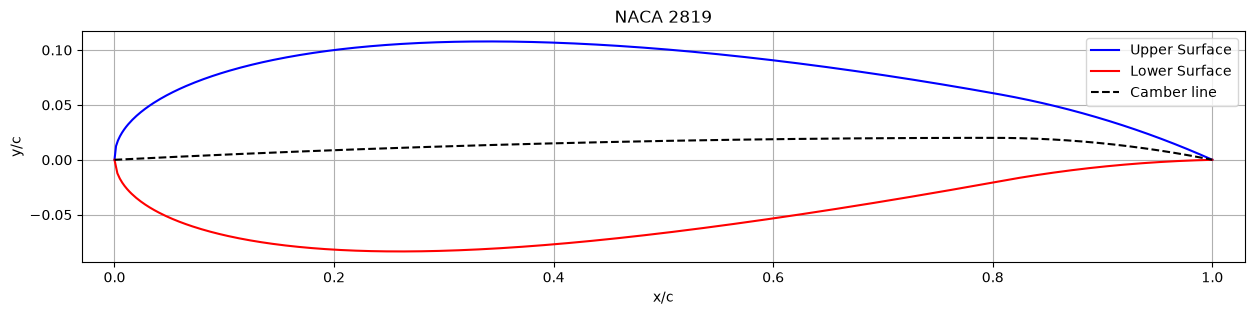

In [25]:

#defining Lagrange code
def Lagrng(x,y,n,xx):
    sum = 0
    for i in range(n):
        product = y[i]
        for j in range(n):
            if i != j:
                product = product*(xx - x[j])/(x[i] - x[j])
        sum = sum + product
    Lagrng = sum
    return Lagrng

#creating the airfoil and its coordinates

#max camber
#m = int(airfoil[0])/100 
m_digit = np.random.randint(0,10)

#location of max camber
#p = int(airfoil[1])/10
p_digit = np.random.randint(1,10)

#max thickness
#t = int(airfoil[2:])/100
t_digits = np.random.randint(5,20)

#if len(airfoil) != 4 or not airfoil.isdigit():
    #raise ValueError("Please input a four digit NACA airfoil.")
m = m_digit/100
p = p_digit/10
t = t_digits/100

print(f"NACA {m_digit}{p_digit}{t_digits:02d}")

print("max camber = ", m)
print("location of max camber = ", p)
print("thickness ratio = ", t)

airfoil_name = f"{m_digit}{p_digit}{t_digits:02d}"
print("Generated airfoil: NACA", airfoil_name)

#chordwise points
x = np.linspace(0,1,500)

#thickness distribution
yt = 5*t*(0.2969*np.sqrt(x)-0.1260*x-0.3516*x**2+0.2843*x**3-0.1036*x**4)

print(yt)

#mean camber line
#yc = np.where(x<p, m/p**2(2*p*x - x**2), m/(1-p)**2*((1-2*p)+2*p*x-x**2))
yc = np.zeros_like(x)
#gradient
dyc_dx = np.zeros_like(x)

for i in range(len(x)):
    if p!=0:
        if x[i]<p:
            yc[i] = (m/p**2)*(2*p*x[i] - x[i]**2)
            dyc_dx[i] = (2*m/p**2)*(p - x[i])
        else: 
            yc[i] = (m/(1-p)**2)*((1-2*p)+ 2*p*x[i] - x[i]**2)
            dyc_dx[i] = (2*m/(1-p)**2)*(p - x[i])

print("yc min =", np.min(yc))
print("yc max =", np.max(yc))

theta = np.arctan(dyc_dx)

#for upper surface
xu = x - yt*np.sin(theta)
yu = yc + yt*np.cos(theta)

#for lower surface
xl = x + yt*np.sin(theta)
yl = yc - yt*np.cos(theta)

plt.figure(figsize=(15,3))

plt.plot(xu, yu, 'b', label='Upper Surface')
plt.plot(xl, yl, 'r', label='Lower Surface')
plt.plot(x, yc, 'k--', label='Camber line')

plt.axis("equal")
plt.grid(True)
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f"NACA {airfoil_name}")
plt.legend()

plt.show()


In [26]:
#Defining cubic spline function
def cubicspline(x,y,xx):
    n=len(x)
    h=np.diff(x)
    A=np.zeros((n,n))
    b=np.zeros(n)

    A[0,0]=1
    A[-1,-1]=1

    for i in range (1,n-1):
        A[i,i-1]=h[i-1]
        A[i,i]= 2*(h[i-1]+h[i])
        A[i,i+1]= h[i]

        b[i]=6*((y[i+1]-y[i])/h[i] - (y[i]-y[i-1])/h[i-1])

    M=np.linalg.solve(A,b)
    yy=np.zeros_like(xx)

    for k, xval in enumerate(xx):
        for i in range(n-1):
            if x[i] <= xval <= x[i+1]:
                hi = x[i+1]-x[i]

                yy[k] = (
                    M[i]*(x[i+1]-xval)**3/(6*hi)
                    + M[i+1]*(xval-x[i])**3/(6*hi)
                    + (y[i]-M[i]*hi**2/6)
                      *(x[i+1]-xval)/hi
                    + (y[i+1]-M[i+1]*hi**2/6)
                      *(xval-x[i])/hi
                )
                break
    return yy


# Results and discussion

**Original airfoil generation:**

The NACA airfoil was generated by selecting values for the maximum camber, the location of maximum camber, and the thickness ratio. These values were used to calculate the upper surface, lower surface, and mean camber line of the airfoil.
The resulting plot shows the expected airfoil shape, with the upper and lower surfaces meeting at the leading and trailing edges. The mean camber line lies between the two surfaces and represents the curvature of the airfoil.

**Lagrange reconstruction of the airfoil:**

Lagrange interpolation was used to reconstruct the upper and lower surfaces of the generated airfoil using a limited number of data points. The interpolation polynomial was evaluated along the chord and compared with the original airfoil coordinates. The accuracy of the reconstruction was evaluated using the maximum absolute error, root mean square (RMS) error, and RMS percentage error.
The results obtained for different numbers of interpolation points are presented below.

| Number of points ($N$) | Maximum Error | RMS Error | RMS Percentage Error |
|:---:|---:|---:|---:|
| 5  | 0.011181 | 0.003277 | 3.173% |
| 10 | 0.007336 | 0.001159 | 1.122% |
| 15 | 0.010777 | 0.001980 | 1.917% |


For ($N=5$), the maximum error was approximately $0.01118$, while the RMS error was $0.00328$. When the number of interpolation points was increased to $10$, both errors decreased. The RMS error reduced to $0.00116$, and the RMS percentage error decreased from $3.173\%$ to $1.122\%$. However, increasing the number of points to $15$ did not further improve the results. The maximum error increased to $0.01078$, and the RMS error increased to $0.00198$. This indicates that increasing the number of interpolation points does not always lead to a more accurate reconstruction.

**Effect of number of interpolation points:**

The plot of RMS error against the number of interpolation points shows a decrease in error from $5$ to $10$ points, followed by an increase at $15$ points. Among the three cases considered, $10$ interpolation points provided the lowest RMS error.
This behaviour can be attributed to the nature of polynomial interpolation. Although increasing the number of points can help represent the airfoil geometry more accurately, a higher-degree polynomial may introduce unwanted variations between the data points. These variations can increase the error, particularly near regions where the airfoil surface changes direction rapidly.
Therefore, selecting a suitable number of interpolation points is important for obtaining an accurate reconstruction.

**The need to improve our results by choosing the spacing between data points:**

The accuracy of interpolation depends not only on the number of points but also on how they are distributed along the airfoil. With uniform spacing, the points are placed at equal intervals along the chord. However, this distribution may not capture regions of rapid curvature as effectively as regions where the surface changes gradually.

An alternative is **cosine spacing**, which places more points near the leading and trailing edges and fewer points around the middle of the chord. This approach may improve the representation of the airfoil geometry near its ends.

Comparing uniform and cosine spacing with the same number of points can help determine which distribution yields a more accurate reconstruction. The maximum and RMS errors should be calculated consistently for both methods before concluding.

**Cubic spline Reconstruction of the airfoil**

The reconstruction accuracy was evaluated using the same interpolation points, $N=5$, $10$, and $15$, used in the Lagrange interpolation study. The maximum error and RMS error were calculated by comparing the spline-reconstructed airfoil with the original airfoil coordinates.

| Number of Points ($N$) | Maximum Error | RMS Error | 
|:---:|---:|---:| 
| 5 | 0.001126 | 0.000794 | 
| 10 | 0.000479 | 0.000794 | 
| 15 | 0.000315 | 0.000794 |

The results show that the cubic spline interpolation reconstructed the airfoil geometry with very small errors for all values of $N$. The maximum error decreased steadily as the number of interpolation points increased from $5$ to $15$, indicating improved geometric accuracy. The RMS error remained very small throughout the study, demonstrating the stability and smoothness of the spline reconstruction. Unlike high-order polynomial interpolation, cubic spline interpolation is performed piecewise over small intervals. This reduces oscillations and allows the reconstructed airfoil to closely follow the original geometry while maintaining smoothness along the entire chord.

**Comparison of Lagrange and Cubic spline interpolation**

A direct comparison was performed between the true airfoil, the Lagrange interpolation reconstruction, and the cubic spline reconstruction. The comparison plot shows that both interpolation methods successfully reproduce the original airfoil geometry. However, the cubic spline reconstruction provides a smoother profile because continuity is enforced between neighbouring spline segments. This reduces the possibility of oscillatory behaviour and improves stability.

**Error Comparison of the two**

| Number of Points ($N$) | Lagrange RMS Error | Cubic Spline RMS Error | Lagrange Maximum Error | Cubic Spline Maximum Error |
|:---:|---:|---:|---:|---:| 
| 5 | 0.003277 | 0.000794 | 0.011181 | 0.001126 | 
| 10 | 0.001159 | 0.000794 | 0.007336 | 0.000479 | 
| 15 | 0.001980 | 0.000794 | 0.010777 | 0.000315 |

The comparison shows that cubic spline interpolation produced smaller maximum errors than Lagrange interpolation for all values of $N$. While the Lagrange interpolation error initially decreased and then increased at $N=15$, the cubic spline interpolation maintained a consistently low error and showed improved accuracy as the number of interpolation points increased. The comparison plot of the true airfoil, Lagrange reconstruction, and cubic spline reconstruction further confirms that both methods accurately reproduce the airfoil shape. However, the cubic spline reconstruction follows the airfoil surface more smoothly and provides a stable representation of the geometry across the entire chord.

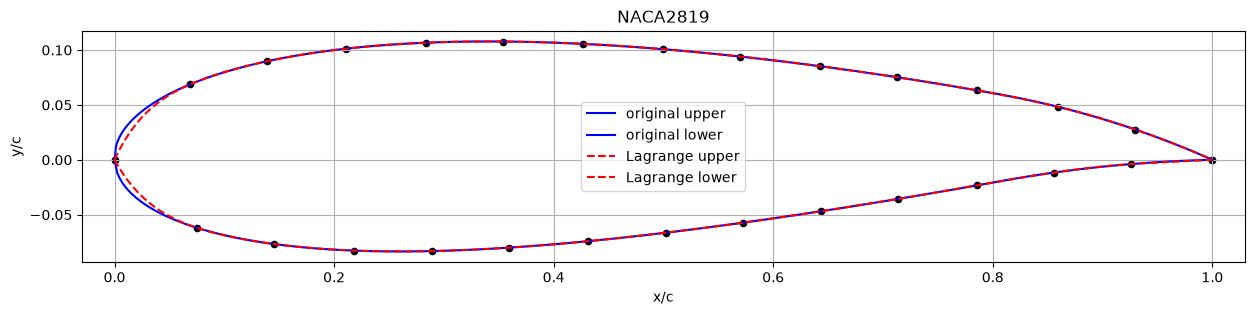

In [27]:
#producing the airfoil using Lagrange function

#N= np.random.randint(10,30)
N_values= [5, 10, 15] 
#print("No. of interpolation points = ", N)
#x_fine = np.linspace(0,1,500)

max_errors_uniform = []
rms_errors_uniform = []
rms_percent_uniform = []

#taking N points from upper surface
#idx_u = np.round(np.linspace(0, len(xu)-1, N)).astype(int)
#xu_data = xu[idx_u]
#yu_data = yu[idx_u]
#taking N points from lower surface
#idx_l = np.round(np.linspace(0, len(xl)-1, N)).astype(int)
#xl_data = xl[idx_l]
#yl_data = yl[idx_l]

for N in N_values:
    x_fine = np.linspace(0,1,500)
    idx_u = np.round(np.linspace(0, len(xu)-1, N)).astype(int)
    xu_data = xu[idx_u]
    yu_data = yu[idx_u]
    
    idx_l = np.round(np.linspace(0, len(xl)-1, N)).astype(int)
    xl_data = xl[idx_l]
    yl_data = yl[idx_l]
#to reconstruct the data for the Lagrange function
    yu_reconstruct = np.array([Lagrng(xu_data, yu_data, N, xx) for xx in x_fine])

    yl_reconstruct = np.array([Lagrng(xl_data, yl_data, N, xx) for xx in x_fine])

#to plot the values
plt.figure(figsize=(15,3))

plt.plot(xu, yu, 'b', label = 'original upper')
plt.plot(xl, yl, 'b', label = 'original lower')

plt. plot(x_fine, yu_reconstruct, 'r--', label='Lagrange upper')
plt.plot(x_fine, yl_reconstruct, 'r--', label='Lagrange lower')

plt.scatter(xu_data, yu_data, color='k', s=20)
plt.scatter(xl_data, yl_data, color='k', s=20)

plt.axis('equal')
plt.grid(True)
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f'NACA{airfoil_name}')
plt.legend()
plt.show()

Upper:
-2.585575203679563e-17 0.10972256928146659
Lower:
-0.08466569377394935 2.5855752036795634e-17

N=5
Maximum Error = 0.02470042947690385
RMS error =  0.007429650949499661
RMS Percentage Error = 6.89168398068616 %
Upper:
-2.5855752036795637e-17 0.10781649477706023
Lower:
-0.0834033983947582 6.065214853541898e-05

N=10
Maximum Error = 0.014764014397621726
RMS error =  0.0024729358343158286
RMS Percentage Error = 2.293875229194566 %
Upper:
-2.585575203679563e-17 0.10780618272839662
Lower:
-0.08348271094136561 2.5855752036795643e-17

N=15
Maximum Error = 0.011302832502612796
RMS error =  0.0014076991085750256
RMS Percentage Error = 1.3057702794026977 %


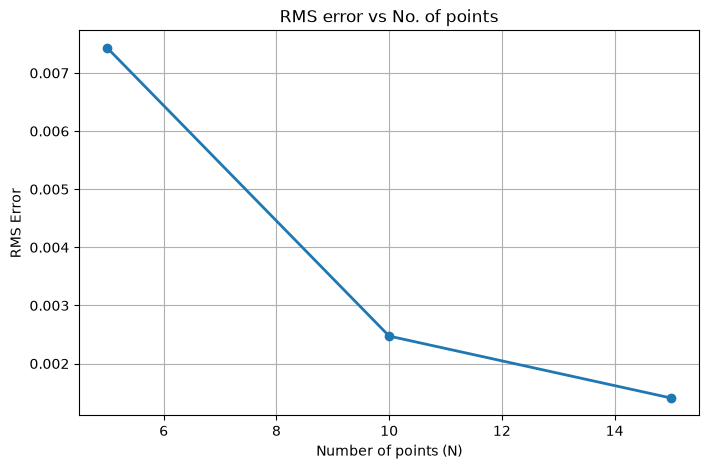

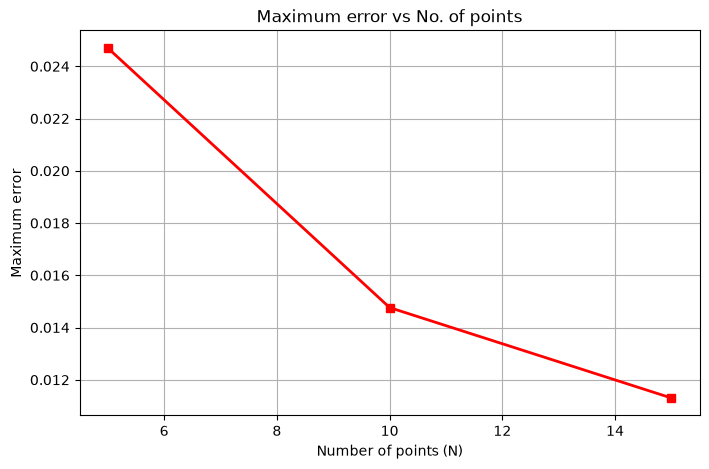

In [28]:
#Quantifying the error (max, RMS) between the true and reconstructed results
x_fine = np.linspace(0,1,500)

max_error_uniform=[]
rms_error_uniform=[]
rms_percent_uniform=[]

for N in N_values:
    #upper surface interpolation pts.
    idx_u = np.round(np.linspace(0, len(xu)-1, N)).astype(int)
    xu_data = xu[idx_u]
    yu_data = yu[idx_u]

    #lower surface interpolation pts.
    idx_l = np.round(np.linspace(0, len(xl)-1, N)).astype(int)
    xl_data = xl[idx_l]
    yl_data = yl[idx_l]

    #Reconstructed upper surface
    y_reconstruct_up = np.array([Lagrng(xu_data, yu_data, N, xx) for xx in x_fine])

    #Reconstructed lower surface
    y_reconstruct_low = np.array([Lagrng(xl_data, yl_data, N, xx) for xx in x_fine])

    #to verify debugging
    print("Upper:")
    print(np.min(y_reconstruct_up), np.max(y_reconstruct_up))

    print("Lower:")
    print(np.min(y_reconstruct_low), np.max(y_reconstruct_low))

    #True airfoil
    y_true_up = np.interp(x_fine, xu, yu)
    y_true_low = np.interp(x_fine, xl, yl)

    y_true = np.concatenate((y_true_up, y_true_low))
    y_reconstruct = np.concatenate((y_reconstruct_up, y_reconstruct_low))

    #Maximum error
    max_error = np.max(np.abs(y_true - y_reconstruct))

    #RMS error
    rms_error = np.sqrt(np.mean((y_true - y_reconstruct)**2))

    #RMS percentage error
    rms_percent = (rms_error/np.max(np.abs(y_true)))*100

    max_error_uniform.append(max_error)
    rms_error_uniform.append(rms_error)
    rms_percent_uniform.append(rms_percent)

    print(f"\nN={N}")
    print("Maximum Error =", max_error)
    print("RMS error = ", rms_error)
    print("RMS Percentage Error =", rms_percent, "%")

plt.figure(figsize=(8,5))
plt.plot(N_values, rms_error_uniform, 'o-', linewidth= 2)
plt.xlabel("Number of points (N)")
plt.ylabel("RMS Error")
plt.title("RMS error vs No. of points")
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(N_values, max_error_uniform, 's-r', linewidth = 2)
plt.xlabel("Number of points (N)")
plt.ylabel("Maximum error")
plt.title("Maximum error vs No. of points")
plt.grid(True)
plt.show()



N=5
Cosine maximum error = 0.021902876569016745
Cosine RMS error = 0.006857875934558392

N=10
Cosine maximum error = 0.010698985994971436
Cosine RMS error = 0.001750781699730694

N=15
Cosine maximum error = 0.007328151028956517
Cosine RMS error = 0.0007943215547936948
N_values= [5, 10, 15]
len(rms_error_uniform) = 3
len(rms_errors_cosine) = 3
len(max_error_uniform) = 3
len(max_errors_cosine) = 3


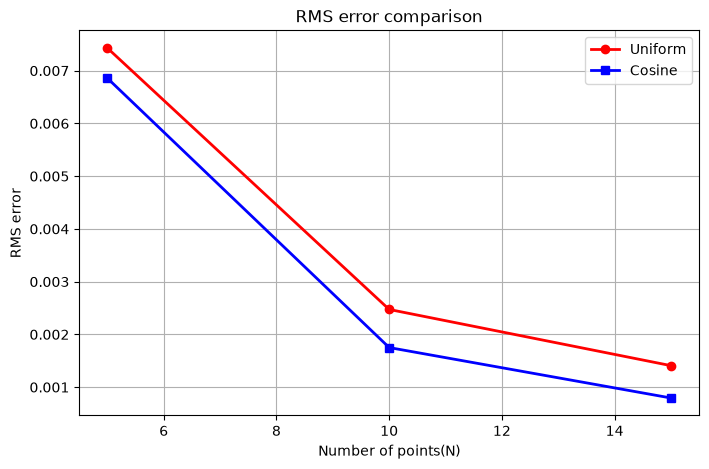

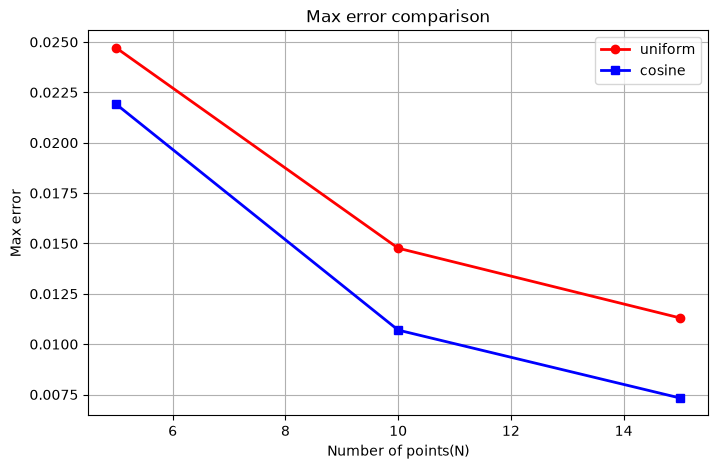

In [29]:
#COSINE SPACING
max_errors_cosine = []
rms_errors_cosine = []

for N in N_values:
    beta = np.linspace(0, np.pi, N)
    x_cos = 0.5*(1-np.cos(beta))

    idx_u = np.array([np.argmin(np.abs(xu-x))for x in x_cos])
    xu_data = xu[idx_u]
    yu_data = yu[idx_u]

    idx_l = np.array([np.argmin(np.abs(xl-x))for x in x_cos])
    xl_data = xl[idx_l]
    yl_data = yl[idx_l]
    y_reconstruct_up = np.array([Lagrng(xu_data, yu_data, N, xx) for xx in x_fine])
    y_reconstruct_low = np.array([Lagrng(xl_data, yl_data, N, xx) for xx in x_fine])
    
    y_true_up = np.interp(x_fine, xu, yu)
    y_true_low = np.interp(x_fine, xl, yl)
    y_true = np.concatenate((y_true_up, y_true_low))
    y_reconstruct= np.concatenate((y_reconstruct_up, y_reconstruct_low))    
    
    max_error = np.max(np.abs(y_true - y_reconstruct))
    rms_error = np.sqrt(np.mean((y_true - y_reconstruct)**2))
    
    max_errors_cosine.append(max_error)
    rms_errors_cosine.append(rms_error)
    
    print(f"\nN={N}")
    print(f"Cosine maximum error = {max_error}")
    print(f"Cosine RMS error = {rms_error}")
#print("\nComparison of Errors")
#print("N\tUniform RMS\tCosine RMS")

#for i in range(len(N_values)):
    #print(f"{N_values[i]}\t"
          #f"{rms_errors_uniform[i]:.6f}\t"
          #f"{rms_errors_cosine[i]:.6f}")

print("N_values=", N_values)

print("len(rms_error_uniform) =", len(rms_error_uniform))
print("len(rms_errors_cosine) =", len(rms_errors_cosine))

print("len(max_error_uniform) =", len(max_error_uniform))
print("len(max_errors_cosine) =", len(max_errors_cosine))

plt.figure(figsize= (8,5))
plt.plot(N_values, rms_error_uniform, 'o-r', linewidth=2, label="Uniform")
plt.plot(N_values, rms_errors_cosine, 's-b', linewidth=2, label="Cosine")
plt.xlabel("Number of points(N)")
plt.ylabel("RMS error")
plt.title("RMS error comparison")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(8,5))
plt.plot(N_values, max_error_uniform, 'o-r', linewidth=2, label='uniform')
plt.plot(N_values, max_errors_cosine, 's-b', linewidth=2, label='cosine')
plt.xlabel('Number of points(N)')
plt.ylabel('Max error')
plt.title('Max error comparison')
plt.grid(True)
plt.legend()
plt.show()


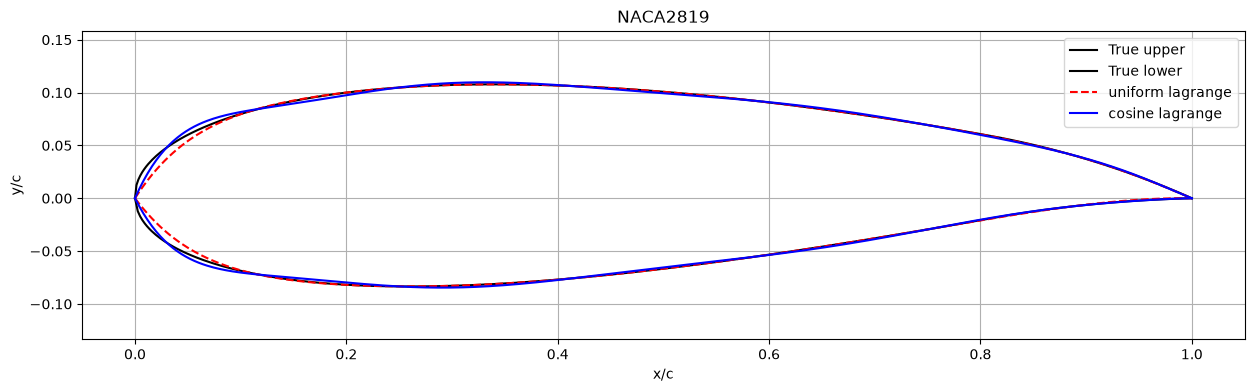

In [30]:
#Airfoil comparison --- true vs uniform Lagrange vs cosine Lagrange

N_plot = 10
x_fine = np.linspace(0,1,500)

idx_u = np.round(np.linspace(0,len(xu)-1, N_plot)).astype(int)
xu_data = xu[idx_u]
yu_data = yu[idx_u]

idx_l = np.round(np.linspace(0,len(xl)-1, N_plot)).astype(int)
xl_data = xl[idx_l]
yl_data = yl[idx_l]

yu_uniform = np.array([Lagrng(xu_data, yu_data, N_plot, xx) for xx in x_fine])
yl_uniform = np.array([Lagrng(xl_data, yl_data, N_plot, xx) for xx in x_fine])

beta= np.linspace(0, np.pi, N_plot)
x_cos = 0.5*(1-np.cos(beta))
idx_u_cos = np.array([np.argmin(np.abs(xu-xx)) for xx in x_cos])
xu_cos_data = xu[idx_u_cos]
yu_cos_data = yu[idx_u_cos]
idx_l_cos = np.array([np.argmin(np.abs(xl-xx)) for xx in x_cos])
xl_cos_data = xl[idx_l_cos]
yl_cos_data = yl[idx_l_cos]

yu_cosine= np.array([Lagrng(xu_cos_data, yu_cos_data, N_plot, xx) for xx in x_fine])
yl_cosine = np.array([Lagrng(xl_cos_data, yl_cos_data, N_plot, xx) for xx in x_fine])


plt.figure(figsize=(15,4))
plt.plot(xu, yu, 'k-', label='True upper')
plt.plot(xl, yl, 'k-', label= 'True lower')
plt.plot(x_fine, yu_uniform, 'r--', label = 'uniform lagrange')
plt.plot(x_fine, yl_uniform, 'r--')
plt.plot(x_fine, yu_cosine, 'b-', label = 'cosine lagrange')
plt.plot(x_fine,yl_cosine, 'b-')

plt.axis('equal')
plt.grid(True)
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f'NACA{airfoil_name}')

plt.legend()
plt.show()

In [31]:
#cubic spline airfoil

N_values = [5,10,15]

x_fine = np.linspace(0,1,500)

y_true_up = np.interp(x_fine, xu, yu)
y_true_low = np.interp(x_fine, xl, yl)
y_true = np.concatenate((y_true_up, y_true_low))

max_errors_spline = []
rms_errors_spline = []

for N in N_values:
    idx_u = np.round(np.linspace(0,len(xu)-1, N)).astype(int)
    idx_l = np.round(np.linspace(0,len(xl)-1,N)).astype(int)

    xu_data = xu[idx_u]
    yu_data = yu[idx_u]
    xl_data = xl[idx_l]
    yl_data = yl[idx_l]

    y_reconstruct_up = cubicspline(xu_data, yu_data, x_fine)
    y_reconstruct_low = cubicspline(xl_data, yl_data, x_fine)
    y_reconstruct = np.concatenate((y_reconstruct_up, y_reconstruct_low))

    max_error = np.max(np.abs(y_true-y_reconstruct)**2)

    max_errors_spline.append(max_error)
    rms_errors_spline.append(rms_error)

    print(f"\nN={N}")
    print("Maximum Error= ", max_error)
    print("RMS Error =", rms_error)


N=5
Maximum Error=  0.0011255317828901734
RMS Error = 0.0007943215547936948

N=10
Maximum Error=  0.00047898259497523046
RMS Error = 0.0007943215547936948

N=15
Maximum Error=  0.00031451447281964
RMS Error = 0.0007943215547936948


Upper x sorted: True
Lower x sorted: True
Upper spline range:
-2.585575203679563e-17 0.10778819454111663
Lower spline range:
-0.0836269311170956 2.5855752036795634e-17


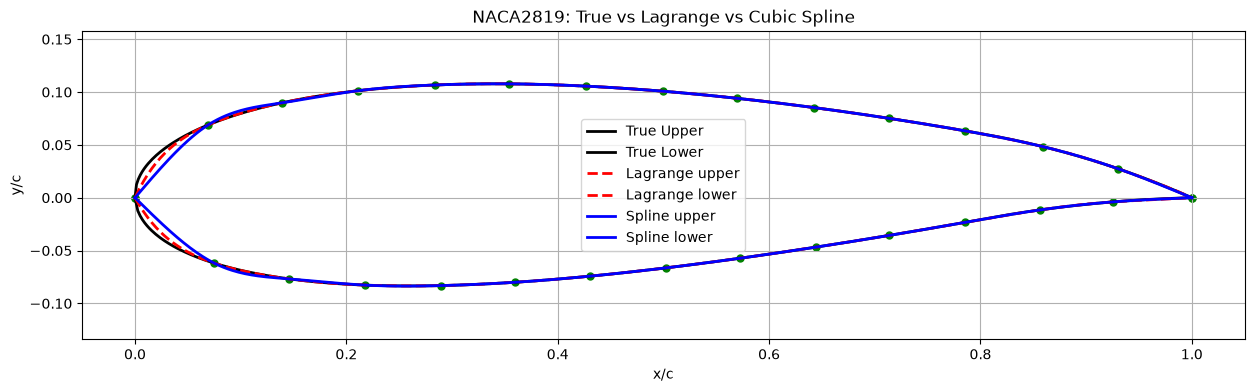

In [32]:
#Airfoil comparison - true vs Lagrange vs Cubic Spline
N=15
x_fine = np.linspace(0,1,500)

idx_u = np.round(np.linspace(0,len(xu)-1,N)).astype(int)
idx_l = np.round(np.linspace(0,len(xl)-1,N)).astype(int)

xu_data = xu[idx_u]
yu_data = yu[idx_u]

xl_data = xl[idx_l]
yl_data = yl[idx_l]

yu_lagrange= np.array([Lagrng(xu_data, yu_data, N, xx)for xx in x_fine])
yl_lagrange= np.array([Lagrng(xl_data, yl_data, N, xx)for xx in x_fine])

upper_sort = np.argsort(xu_data)

xu_data = xu_data[upper_sort]
yu_data = yu_data[upper_sort]

lower_sort = np.argsort(xl_data)

xl_data = xl_data[lower_sort]
yl_data = yl_data[lower_sort]

yu_spline = cubicspline(xu_data, yu_data, x_fine)
yl_spline = cubicspline(xl_data, yl_data, x_fine)

print("Upper x sorted:",
      np.all(np.diff(xu_data) > 0))

print("Lower x sorted:",
      np.all(np.diff(xl_data) > 0))

print("Upper spline range:")
print(np.min(yu_spline),
      np.max(yu_spline))

print("Lower spline range:")
print(np.min(yl_spline),
      np.max(yl_spline))

plt.figure(figsize=(15,4))

#true airfoil
plt.plot(xu,yu, 'k-', linewidth=2, label='True Upper')
plt.plot(xl,yl,'k-', linewidth=2, label='True Lower')

#Lagrange airfoil
plt.plot(x_fine, yu_lagrange,'r--', linewidth=2,label='Lagrange upper')
plt.plot(x_fine, yl_lagrange,'r--',linewidth=2, label='Lagrange lower')

#cubic spline
plt.plot(x_fine,yu_spline,'b-',linewidth=2, label='Spline upper')
plt.plot(x_fine, yl_spline,'b-', linewidth=2, label='Spline lower')

plt.scatter(xu_data,yu_data, color='green',s=25)
plt.scatter(xl_data, yl_data, color='green',s=25)

plt.axis('equal')
plt.grid(True)

plt.xlabel('x/c')
plt.ylabel('y/c')

plt.title(f'NACA{airfoil_name}: True vs Lagrange vs Cubic Spline')
plt.legend(loc='best')
plt.show()



Error Comparison
Lagrange RMS error = 0.001408
Lagrange Maximum error = 0.011303
Cubic Spline RMS error = 0.003053
Cubic Spline Maximum error = 0.017735


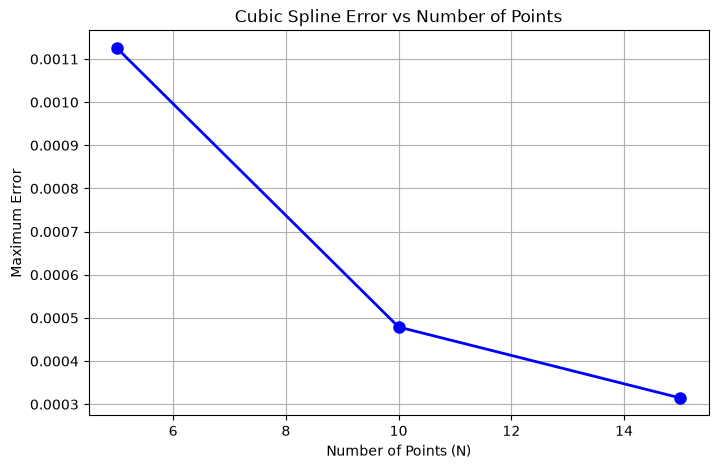

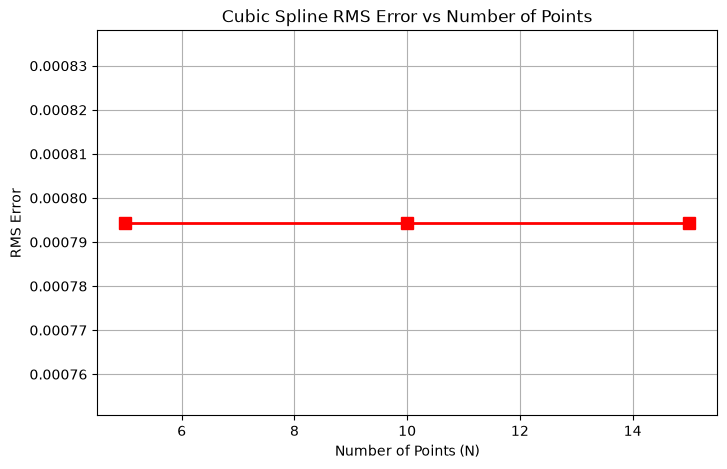

In [34]:
#error comparison

y_true_up = np.interp(x_fine, xu, yu)
y_true_low = np.interp(x_fine, xl, yl)
y_true = np.concatenate((y_true_up, y_true_low))

y_lagrange = np.concatenate((yu_lagrange, yl_lagrange))
lagrange_max = np.max(np.abs(y_true - y_lagrange))
lagrange_rms = np.sqrt(np.mean((y_true - y_lagrange)**2))

y_spline = np.concatenate((yu_spline, yl_spline))
spline_max = np.max(np.abs(y_true - y_spline))
spline_rms = np.sqrt(np.mean((y_true - y_spline)**2))

print("\nError Comparison")

print(f"Lagrange RMS error = {lagrange_rms:.6f}")
print(f"Lagrange Maximum error = {lagrange_max:.6f}")

print(f"Cubic Spline RMS error = {spline_rms:.6f}")
print(f"Cubic Spline Maximum error = {spline_max:.6f}")

plt.figure(figsize=(8,5))

plt.plot(N_values, max_errors_spline, 'o-b', linewidth=2, markersize=8)

plt.xlabel('Number of Points (N)')
plt.ylabel('Maximum Error')
plt.title('Cubic Spline Error vs Number of Points')
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))

plt.plot(N_values, rms_errors_spline, 's-r', linewidth=2, markersize=8)

plt.xlabel('Number of Points (N)')
plt.ylabel('RMS Error')
plt.title('Cubic Spline RMS Error vs Number of Points')
plt.grid(True)
plt.show()

# Summary and conculsions

A cambered NACA 4-digit airfoil was generated using randomly selected values of camber, camber location, and thickness. The upper and lower surfaces were then reconstructed using a user-defined Lagrange interpolation function with a limited number of data points.

The reconstruction accuracy was evaluated for $5$, $10$, and $15$ interpolation points using the maximum error, RMS error, and RMS percentage error. Among these cases, $10$ points gave the lowest RMS error. However, increasing the number of points to $15$ did not further improve the results, showing that a higher number of points does not always guarantee better accuracy.

The study also considered the effect of data-point spacing on the reconstruction. Uniform spacing distributes the points at equal intervals along the chord, whereas cosine spacing places more points near the leading and trailing edges, where the airfoil curvature changes more rapidly. This makes cosine spacing a useful alternative for capturing the airfoil shape near these regions. A comparison of the two methods can help determine which spacing provides better accuracy for a given number of points.

A natural cubic spline interpolation method was also implemented without using the SciPy library. The spline reconstruction was performed using the same interpolation points as the Lagrange method and was evaluated using maximum and RMS error measures. The cubic spline produced a smooth and continuous representation of the airfoil surface and accurately captured the airfoil geometry over the entire chord length.

A comparison of the true airfoil, Lagrange interpolation, and cubic spline interpolation showed that both interpolation methods were able to reconstruct the airfoil successfully. However, the cubic spline curve followed the true airfoil more smoothly and avoided the oscillatory behaviour that can occur in polynomial interpolation. The error analysis and comparison plots demonstrated the differences between the two approaches and highlighted the advantages of piecewise cubic spline interpolation for airfoil reconstruction.

Overall, the results highlight that the accuracy of interpolation depends on both the number and distribution of data points, as well as the interpolation method used. Choosing a suitable point spacing and interpolation technique can significantly improve the reconstruction of airfoil geometry. For the cases considered in this study, cosine spacing improved the Lagrange reconstruction accuracy, while cubic spline interpolation provided a smooth and reliable representation of the airfoil surface.

# References

1. [Airfoil details and equations](https://en.wikipedia.org/wiki/NACA_airfoil)
2. [Lagrange Interpolation Formula](https://en.wikipedia.org/wiki/Lagrange_polynomial)
3. [RMS vs max erros](https://share.google/aimode/dCfXbYBn8gFXzCs2w)
4. [Cosine plot error rectification](https://chatgpt.com/s/t_6ad45e0d9efc8191b2404c2ca94bb655)
5. [True vs Uniform Lagrange vs Cosine Lagrange Airfoil comparison error rectification](https://chatgpt.com/s/t_6ad463c4f9e081918af94f0ec8b012ca)
6. [Cubic Spline](https://www.geeksforgeeks.org/machine-learning/cubic-spline-interpolation/)